# 01 · Multimodal embeddings with CLIP and SigLIP

This notebook sets up everything the other two need:

1. Load two **frozen** image–text models: OpenAI **CLIP** ViT-B/32 and Google **SigLIP** ViT-B/16.
2. Load two datasets that sit at opposite ends of "what the internet has seen":
   * **Oxford-IIIT Pets**: 37 cat and dog breeds in everyday photos. Close to CLIP's training data.
   * **PathMNIST**: 9 tissue types in H&E-stained colorectal histology tiles. Far from it.
3. Look at the **shared embedding space**: images and sentences end up as vectors you can compare with a dot product.
4. Embed every image once with each model and **cache** the vectors in `data/emb/`. Notebooks 02 and 03 only read that cache.

See [README.md](README.md) for the diagrams and background.

In [1]:
%load_ext autoreload
%autoreload 2
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch

import clip_utils as cu

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("device:", cu.DEVICE, "| torch", torch.__version__, "| CPU threads", torch.get_num_threads())

device: cpu | torch 2.2.2 | CPU threads 4


## 1. Load the two models

Both models have the same two-tower shape: an **image encoder** (a Vision Transformer) and a **text encoder** (a Transformer), each ending in a vector of the same size. Training pulled matching image–caption pairs together and pushed mismatched ones apart, so the two towers learned a common coordinate system.

What differs is the training loss and the data:

| | CLIP ViT-B/32 | SigLIP ViT-B/16 |
|---|---|---|
| Training pairs | 400M (WIT, OpenAI) | ~10B (WebLI, Google) |
| Loss | softmax over the batch (each image picks its caption from all captions) | sigmoid per pair (each image–caption pair is a yes/no question) |
| Image patches | 32×32 px → 49 tokens | 16×16 px → 196 tokens |

In [2]:
models = {k: cu.load_model(k) for k in cu.MODELS}

for k, (m, p) in models.items():
    n_vis = sum(x.numel() for x in m.vision_model.parameters()) / 1e6
    n_txt = sum(x.numel() for x in m.text_model.parameters()) / 1e6
    dim = cu.encode_texts(m, p, ["a photo of a cat"]).shape[1]
    scale, bias = cu.logit_params(m)
    print(f"{k:7s} {cu.MODELS[k]:32s} vision {n_vis:5.1f}M | text {n_txt:5.1f}M | "
          f"embedding dim {dim} | logit scale {scale:6.1f} | logit bias {bias:6.2f}")

.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


clip    openai/clip-vit-base-patch32     vision  87.5M | text  63.2M | embedding dim 512 | logit scale  100.0 | logit bias   0.00


siglip  google/siglip-base-patch16-224   vision  92.9M | text 110.3M | embedding dim 768 | logit scale  117.3 | logit bias -12.93


The **logit scale** is a learned temperature. Cosine similarities live in [-1, 1] and in practice differ by only a few hundredths between the right and wrong caption. Multiplying by ~100 turns those small gaps into confident probabilities. SigLIP also learns a **bias** (a large negative number), because under its sigmoid loss almost every image–text pair in a batch is a negative.

## 2. Load the datasets

Only a subsample per class is used (see `SPLIT_SIZES` in [clip_utils.py](clip_utils.py)) so the whole project runs on a laptop CPU. The split matters:

* **test** images are what every method is scored on.
* **train** images are used only by the linear probe in notebook 03. Zero-shot never sees them.

In [3]:
sets = {}
for name in ["pets", "pathmnist"]:
    for split in ["train", "test"]:
        s = cu.load_imageset(name, split)
        sets[name, split] = s
        print(f"{name:10s} {split:5s} {len(s):5d} images | {len(s.classnames)} classes | "
              f"{np.bincount(s.labels).min()}-{np.bincount(s.labels).max()} per class")

pets       train  1850 images | 37 classes | 50-50 per class


pets       test   1110 images | 37 classes | 30-30 per class


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Using downloaded and verified file: data/medmnist/pathmnist_64.npz


pathmnist  train   450 images | 9 classes | 50-50 per class


Using downloaded and verified file: data/medmnist/pathmnist_64.npz


pathmnist  test    900 images | 9 classes | 100-100 per class


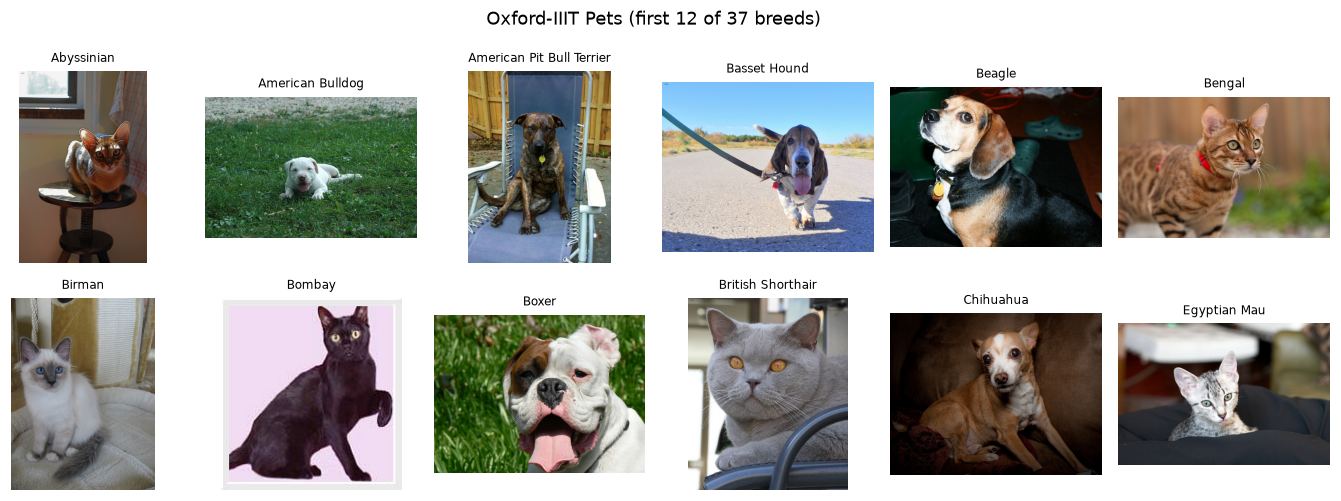

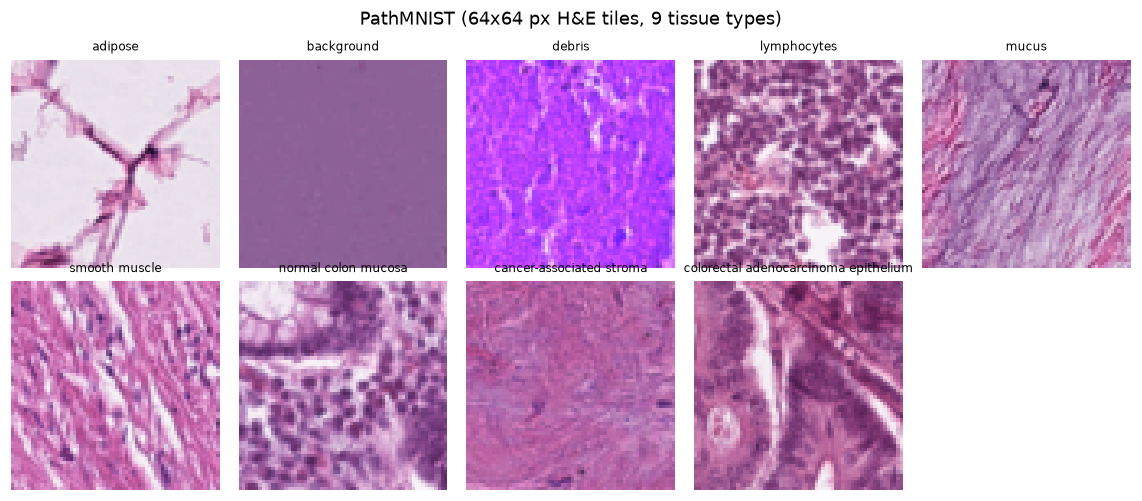

In [4]:
def show_one_per_class(s, max_classes=12, ncols=6):
    classes = list(range(min(len(s.classnames), max_classes)))
    nrows = int(np.ceil(len(classes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.1 * ncols, 2.3 * nrows))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, c in zip(axes.ravel(), classes):
        i = int(np.flatnonzero(s.labels == c)[0])
        ax.imshow(s.image(i))
        ax.set_title(s.classnames[c], fontsize=8)
    return fig

fig = show_one_per_class(sets["pets", "test"])
fig.suptitle("Oxford-IIIT Pets (first 12 of 37 breeds)")
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "examples_pets.png", bbox_inches="tight")

fig = show_one_per_class(sets["pathmnist", "test"], ncols=5)
fig.suptitle(f"PathMNIST ({cu.PATHMNIST_SIZE}x{cu.PATHMNIST_SIZE} px H&E tiles, 9 tissue types)")
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "examples_pathmnist.png", bbox_inches="tight")

## 3. The shared space in one picture

Take six images and six captions, embed all twelve, and compute every image–caption cosine similarity. If the space is truly shared, each image should be most similar to its own caption (the diagonal).

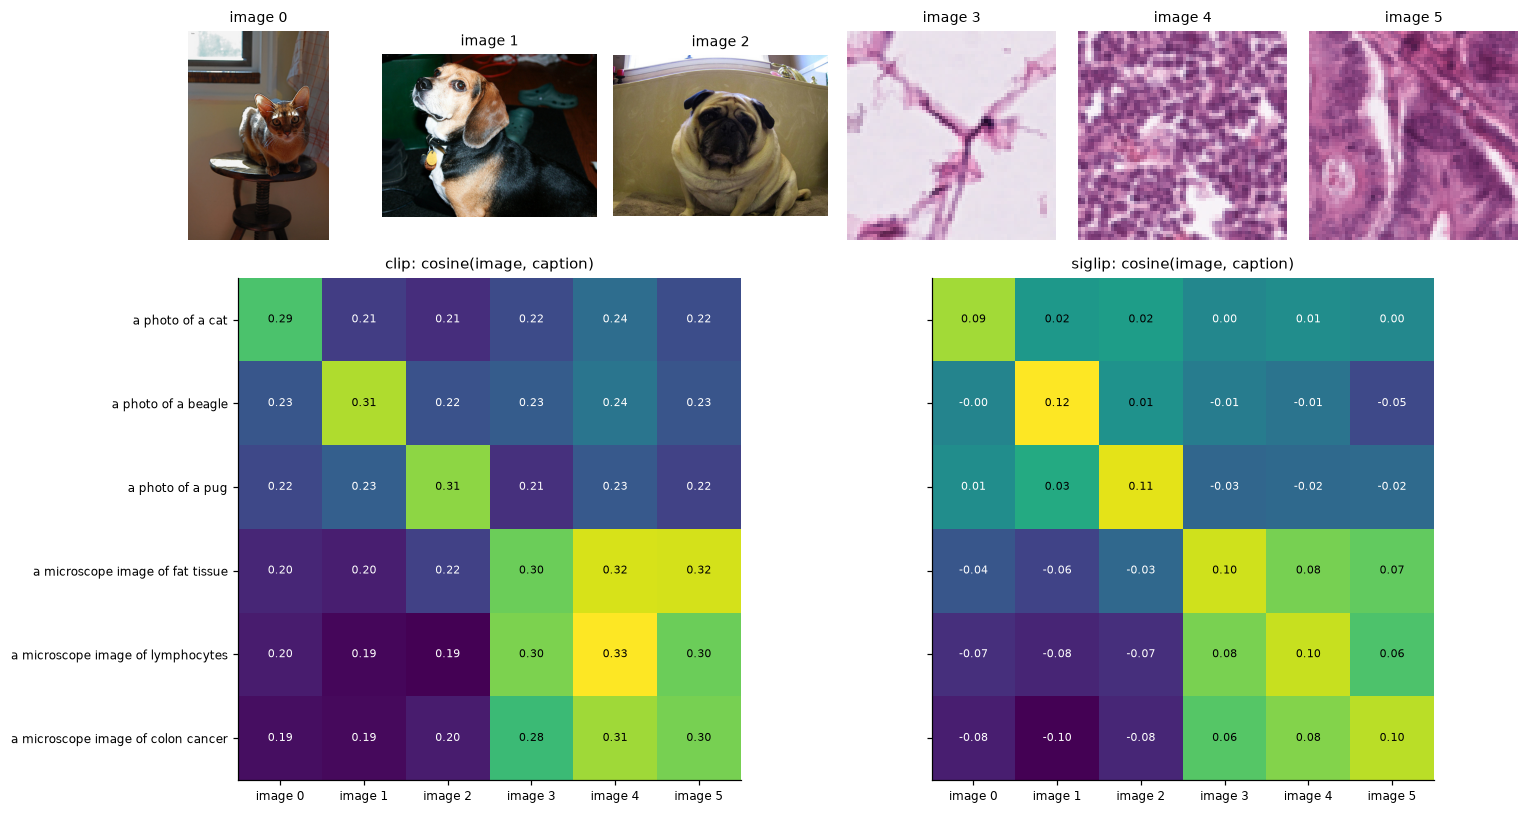

In [5]:
demo = [  # (dataset, class name, caption)
    ("pets", "Abyssinian", "a photo of a cat"),
    ("pets", "Beagle", "a photo of a beagle"),
    ("pets", "Pug", "a photo of a pug"),
    ("pathmnist", "adipose", "a microscope image of fat tissue"),
    ("pathmnist", "lymphocytes", "a microscope image of lymphocytes"),
    ("pathmnist", "colorectal adenocarcinoma epithelium", "a microscope image of colon cancer"),
]
demo_imgs = []
for name, cls, _ in demo:
    s = sets[name, "test"]
    demo_imgs.append(s.image(int(np.flatnonzero(s.labels == s.classnames.index(cls))[0])))
captions = [c for *_, c in demo]

fig = plt.figure(figsize=(14, 7.5))
gs = fig.add_gridspec(2, 12, height_ratios=[1, 2.4])
for j, img in enumerate(demo_imgs):
    ax = fig.add_subplot(gs[0, 2 * j:2 * j + 2])
    ax.imshow(img)
    ax.set_title(f"image {j}", fontsize=9)
    ax.axis("off")
for k, (key, (m, p)) in enumerate(models.items()):
    sim = cu.encode_images(m, p, demo_imgs) @ cu.encode_texts(m, p, captions).T  # (images, captions)
    ax = fig.add_subplot(gs[1, 6 * k:6 * k + 6])
    ax.imshow(sim.T, cmap="viridis")
    ax.set_xticks(range(6), [f"image {j}" for j in range(6)], fontsize=8)
    ax.set_yticks(range(6), captions if k == 0 else [], fontsize=8)
    for (i, j), v in np.ndenumerate(sim.T):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="black" if v > sim.mean() else "white")
    ax.set_title(f"{key}: cosine(image, caption)", fontsize=10)
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "shared_space_demo.png", bbox_inches="tight")

Two things to notice:

* The **absolute values are small**: about 0.19–0.33 for CLIP and −0.10 to 0.12 for SigLIP. A matching pair is not "close" in an absolute sense, only *closer than the alternatives*. Zero-shot classification only needs the ranking, which is why it works anyway. (The two models' scales differ too, so never compare raw cosines across models.)
* For the pets, both models light up the diagonal cleanly. For the histology tiles, CLIP clearly knows they are "microscope images" (the whole lower-right block is bright) but barely distinguishes fat from lymphocytes from cancer: each tile scores ~0.30–0.33 against all three captions. SigLIP does a bit better. Neither saw many captioned H&E slides.

## 4. Embed every image (cached)

Each image becomes one unit-length vector. This is the only expensive step in the project; after it, every experiment is matrix algebra on a few thousand vectors. On this CPU, CLIP B/32 takes a couple of minutes and SigLIP B/16 roughly four times longer.

In [6]:
for key, (m, p) in models.items():
    for (name, split), s in sets.items():
        t0 = time.time()
        E = cu.embed_imageset(key, s, model=m, processor=p)
        print(f"{key:7s} {name:10s} {split:5s} -> {E.shape}  ({time.time() - t0:.0f}s, "
              f"norms {np.linalg.norm(E, axis=1).min():.3f}-{np.linalg.norm(E, axis=1).max():.3f})")

clip pets train:   0%|          | 0/58 [00:00<?, ?it/s]

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


clip pets train:   2%|▏         | 1/58 [00:01<01:25,  1.51s/it]

clip pets train:   3%|▎         | 2/58 [00:03<01:28,  1.59s/it]

clip pets train:   5%|▌         | 3/58 [00:04<01:26,  1.57s/it]

...

siglip pathmnist test:  93%|█████████▎| 27/29 [02:27<00:11,  5.58s/it]

siglip pathmnist test:  97%|█████████▋| 28/29 [02:33<00:05,  5.43s/it]

siglip pathmnist test: 100%|██████████| 29/29 [02:33<00:00,  3.99s/it]

siglip pathmnist test: 100%|██████████| 29/29 [02:33<00:00,  5.30s/it]

siglip  pathmnist  test  -> (900, 768)  (154s, norms 1.000-1.000)


## 5. The modality gap

Images and texts share a space, but they don't mix evenly in it. Each modality sits in its own narrow cone, and the two cones are offset from each other (Liang et al., 2022, *Mind the Gap*). You can see this by comparing three kinds of cosine similarity on the Pets test set:

* image vs. image
* text vs. text (one prompt per breed)
* image vs. the text of its own breed

If the modality gap exists, image–text similarities will be lower than *both* within-modality similarities, even for correct pairs.

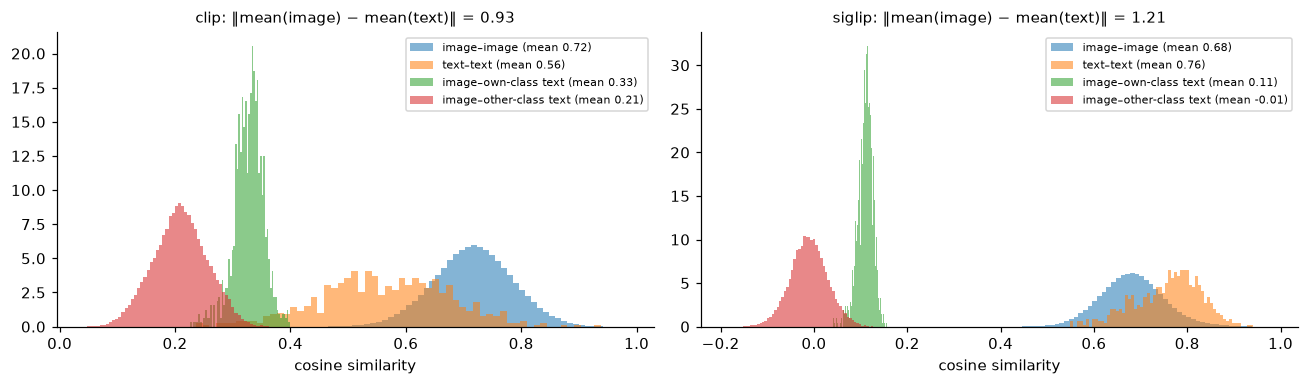

In [7]:
s = sets["pets", "test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, (key, (m, p)) in zip(axes, models.items()):
    E = cu.embed_imageset(key, s)
    T = cu.encode_texts(m, p, [f"a photo of a {c}, a type of pet." for c in s.classnames])
    iu_e, iu_t = np.triu_indices(len(E), 1), np.triu_indices(len(T), 1)
    groups = {
        "image–image": (E @ E.T)[iu_e],
        "text–text": (T @ T.T)[iu_t],
        "image–own-class text": (E * T[s.labels]).sum(1),
        "image–other-class text": (E @ T.T)[np.arange(len(T))[None, :] != s.labels[:, None]],
    }
    for label, v in groups.items():
        ax.hist(v, bins=60, density=True, alpha=0.55, label=f"{label} (mean {v.mean():.2f})")
    gap = np.linalg.norm(E.mean(0) - T.mean(0))
    ax.set_title(f"{key}: ‖mean(image) − mean(text)‖ = {gap:.2f}", fontsize=10)
    ax.set_xlabel("cosine similarity")
    ax.legend(fontsize=7.5)
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "modality_gap.png", bbox_inches="tight")

What the histograms show:

* **The gap.** Every image–text similarity (green, red) is far below the within-modality similarities (blue, orange). Even a correct image–caption pair scores ~0.33 (CLIP) or ~0.11 (SigLIP), while two random pet photos score ~0.7. The two modalities live in separate regions; the offset between their centroids is 0.93 (CLIP) and 1.21 (SigLIP) on a unit sphere.
* **The signal is in the small difference.** Within the image–text band, own-class text (green) sits reliably above other-class text (red): 0.33 vs. 0.21 for CLIP, 0.11 vs. −0.01 for SigLIP. That narrow margin, multiplied by the logit scale of ~100, is what zero-shot classification runs on.

## 6. Are the classes separable before any text is involved?

UMAP squeezes the 512-D (CLIP) or 768-D (SigLIP) image embeddings into 2-D. No labels are used to make the map; color is added afterwards. Tight, separate clusters mean the image encoder already organizes the data by class. That is exactly what a linear probe exploits in notebook 03, whether or not the *text* encoder knows the class names.

.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


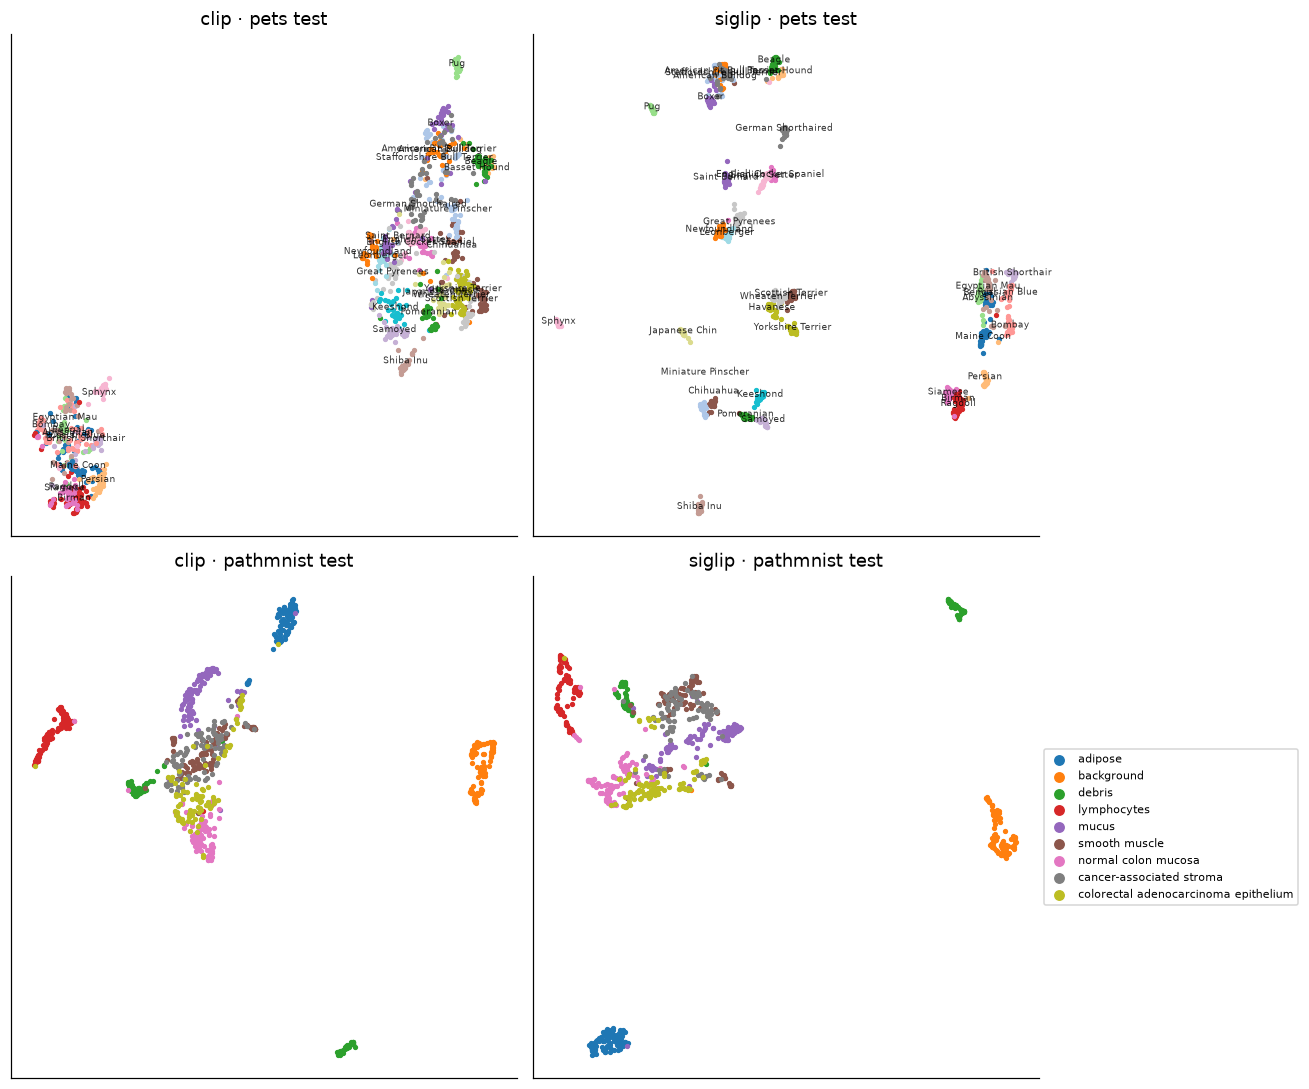

In [8]:
import umap

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row, name in enumerate(["pets", "pathmnist"]):
    s = sets[name, "test"]
    cmap = plt.get_cmap("tab20" if len(s.classnames) > 10 else "tab10")
    for col, key in enumerate(models):
        xy = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=0).fit_transform(
            cu.embed_imageset(key, s))
        ax = axes[row, col]
        for c, cname in enumerate(s.classnames):
            pts = xy[s.labels == c]
            ax.scatter(*pts.T, s=6, color=cmap(c % 20), label=cname if name == "pathmnist" else None)
            if name == "pets":
                ax.annotate(cname, pts.mean(0), fontsize=6, ha="center", alpha=0.8)
        ax.set_title(f"{key} · {name} test")
        ax.set_xticks([]); ax.set_yticks([])
    if name == "pathmnist":
        axes[row, 1].legend(fontsize=7, markerscale=2.5, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "umap.png", bbox_inches="tight")

## Takeaways

* Both models map images and text into one space where **a dot product means "how well does this caption fit this image"**.
* Absolute similarities are small and the two modalities sit apart (the modality gap). Classification works on **rankings**, not absolute values.
* The image embeddings cluster by class for both datasets, including histology. Keep that in mind for notebook 02: if zero-shot fails on PathMNIST, it may be the **text side** (or the bridge between text and image) that fails, not the image features.

Next: [02_zero_shot.ipynb](02_zero_shot.ipynb).